---
title: "October 2026 Near-Earth Object (NEO) Monthly Review & Synthesis"
author: "Thurston Douglas Norris"
affiliations: "Independent Researcher / Amateur Astronomer (Kubuntu Linux / Python Scientific Stack)"
date: "2026-11-01"
project_id: "NEO-MONTHLY-SYNTHESIS-2026-10"
repository_url: "https://github.com/thnorris13/NEO_Project"
data_source: "NASA Near Earth Object Web Service (NeoWs) API / JPL Small-Body Database"
software_environment:
  python_version: "3.10+"
  core_libraries: ["pandas", "matplotlib", "seaborn", "requests"]
license: "MIT"
status: "Completed / Publication Ready"
---

# Executive Summary & Scientific Objective
This notebook provides a comprehensive, multi-week data ingestion, telemetry unification, and exploratory data analysis (EDA) synthesis of Near-Earth Objects (NEOs) close-approaching Earth during October 2026.

## Methodology & Parameter Definitions
* **Temporal Scope:** October 1, 2026, through October 28, 2026, aggregated across four sequential 7-day query windows to comply with API rate limits.
* **Miss Distance:** Measured in both absolute kilometers ($km$) and normalized Lunar Distances ($LD$, where $1\ LD \approx 384,400\ km$).
* **Relative Velocity:** Expressed in kilometers per hour ($km/h$) relative to Earth's geocentric frame.
* **Estimated Diameter:** Calculated using absolute magnitude ($H$) conversion bounds, expressed as minimum and maximum diameter in meters ($m$).
* **Hazard Classification:** Evaluated via NASA's `is_potentially_hazardous_asteroid` boolean parameter based on minimum orbit intersection distance (MOID) and absolute magnitude thresholds.

## Data Provenance & Reproducibility
All telemetry records were programmatically queried via the NASA NeoWs REST API, validated for schema integrity, purged of boundary duplicates, and persisted to persistent cloud storage at `/content/drive/MyDrive/Projects/NEO_Project/October_2026_Full_Monthly_NEO_Telemetry.csv`.

In [ ]:
from google.colab import drive
import os

# Mount Google Drive to workspace
drive.mount('/content/drive')

# Ensure working directory points to our project folder
project_dir = '/content/drive/MyDrive/Projects/NEO_Project'
os.makedirs(project_dir, exist_ok=True)
os.chdir(project_dir)

print(f"Current Working Directory: {os.getcwd()}")
print("Google Drive mounted successfully and project directory verified.")

Mounted at /content/drive
Current Working Directory: /content/drive/MyDrive/Projects/NEO_Project
Google Drive mounted successfully and project directory verified.


## Phase 2: Data Ingestion & Schema Validation
In this phase, we load the consolidated October 2026 Near-Earth Object telemetry dataset compiled from the four sequential API query windows. We verify data types, check for null values, and print baseline descriptive statistics.

In [ ]:
import pandas as pd
import numpy as np

# Define dataset path in Google Drive
dataset_path = '/content/drive/MyDrive/Projects/NEO_Project/October_2026_Full_Monthly_NEO_Telemetry.csv'

# Load dataset into Pandas DataFrame
df_neo = pd.read_csv(dataset_path)

# Display basic dataset info and dimensions
print("=== Dataset Shape & Structure ===")
print(f"Total Records: {df_neo.shape[0]}")
print(f"Total Features: {df_neo.shape[1]}")
print("\n=== Column Data Types & Non-Null Counts ===")
print(df_neo.info())

# Display first few rows to confirm ingestion integrity
print("\n=== First 5 Records Preview ===")
display(df_neo.head())

# Quick check for missing values
missing_counts = df_neo.isnull().sum()
if missing_counts.sum() == 0:
    print("\n[Validation Check Passed]: Zero missing values detected across all telemetry features.")
else:
    print("\n[Warning]: Missing values detected:")
    print(missing_counts[missing_counts > 0])

=== Dataset Shape & Structure ===
Total Records: 169
Total Features: 8

=== Column Data Types & Non-Null Counts ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 169 entries, 0 to 168
Data columns (total 8 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Name                             169 non-null    object 
 1   Close Approach Date              169 non-null    object 
 2   Estimated Diameter Min (m)       169 non-null    float64
 3   Estimated Diameter Max (m)       169 non-null    float64
 4   Miss Distance (Lunar Distances)  169 non-null    float64
 5   Miss Distance (km)               169 non-null    float64
 6   Velocity (km/h)                  169 non-null    float64
 7   Potentially Hazardous            169 non-null    bool   
dtypes: bool(1), float64(5), object(2)
memory usage: 9.5+ KB
None

=== First 5 Records Preview ===


,Name,Close Approach Date,Estimated Diameter Min (m),Estimated Diameter Max (m),Miss Distance (Lunar Distances),Miss Distance (km),Velocity (km/h),Potentially Hazardous
0,(2019 SD7),2026-10-01,48.367649,108.153351,113.044345,4.347350e+07,30662.228198,False
1,(2018 LC1),2026-10-01,27.832677,62.235757,186.944291,7.189323e+07,30361.516394,False
2,(2016 FB),2026-10-01,49.040510,109.657914,167.492593,6.441269e+07,39904.904307,False
3,(2014 RX22),2026-10-01,16.770846,37.500752,98.173566,3.775464e+07,46816.095698,False
4,(2008 TX3),2026-10-01,27.832677,62.235757,171.374897,6.590571e+07,60405.274473,False



[Validation Check Passed]: Zero missing values detected across all telemetry features.


## Phase 3: Exploratory Data Analysis & Publication-Ready Visualizations
In this phase, we analyze the statistical distribution of Near-Earth Objects, separating potentially hazardous asteroids (PHAs) from non-hazardous bodies. We generate high-resolution scatter and distribution plots adhering to scientific journal formatting standards.

[Visualization Saved]: High-resolution plot exported successfully to:
/content/drive/MyDrive/Projects/NEO_Project/visualizations/October_2026_NEO_Velocity_vs_MissDistance.png


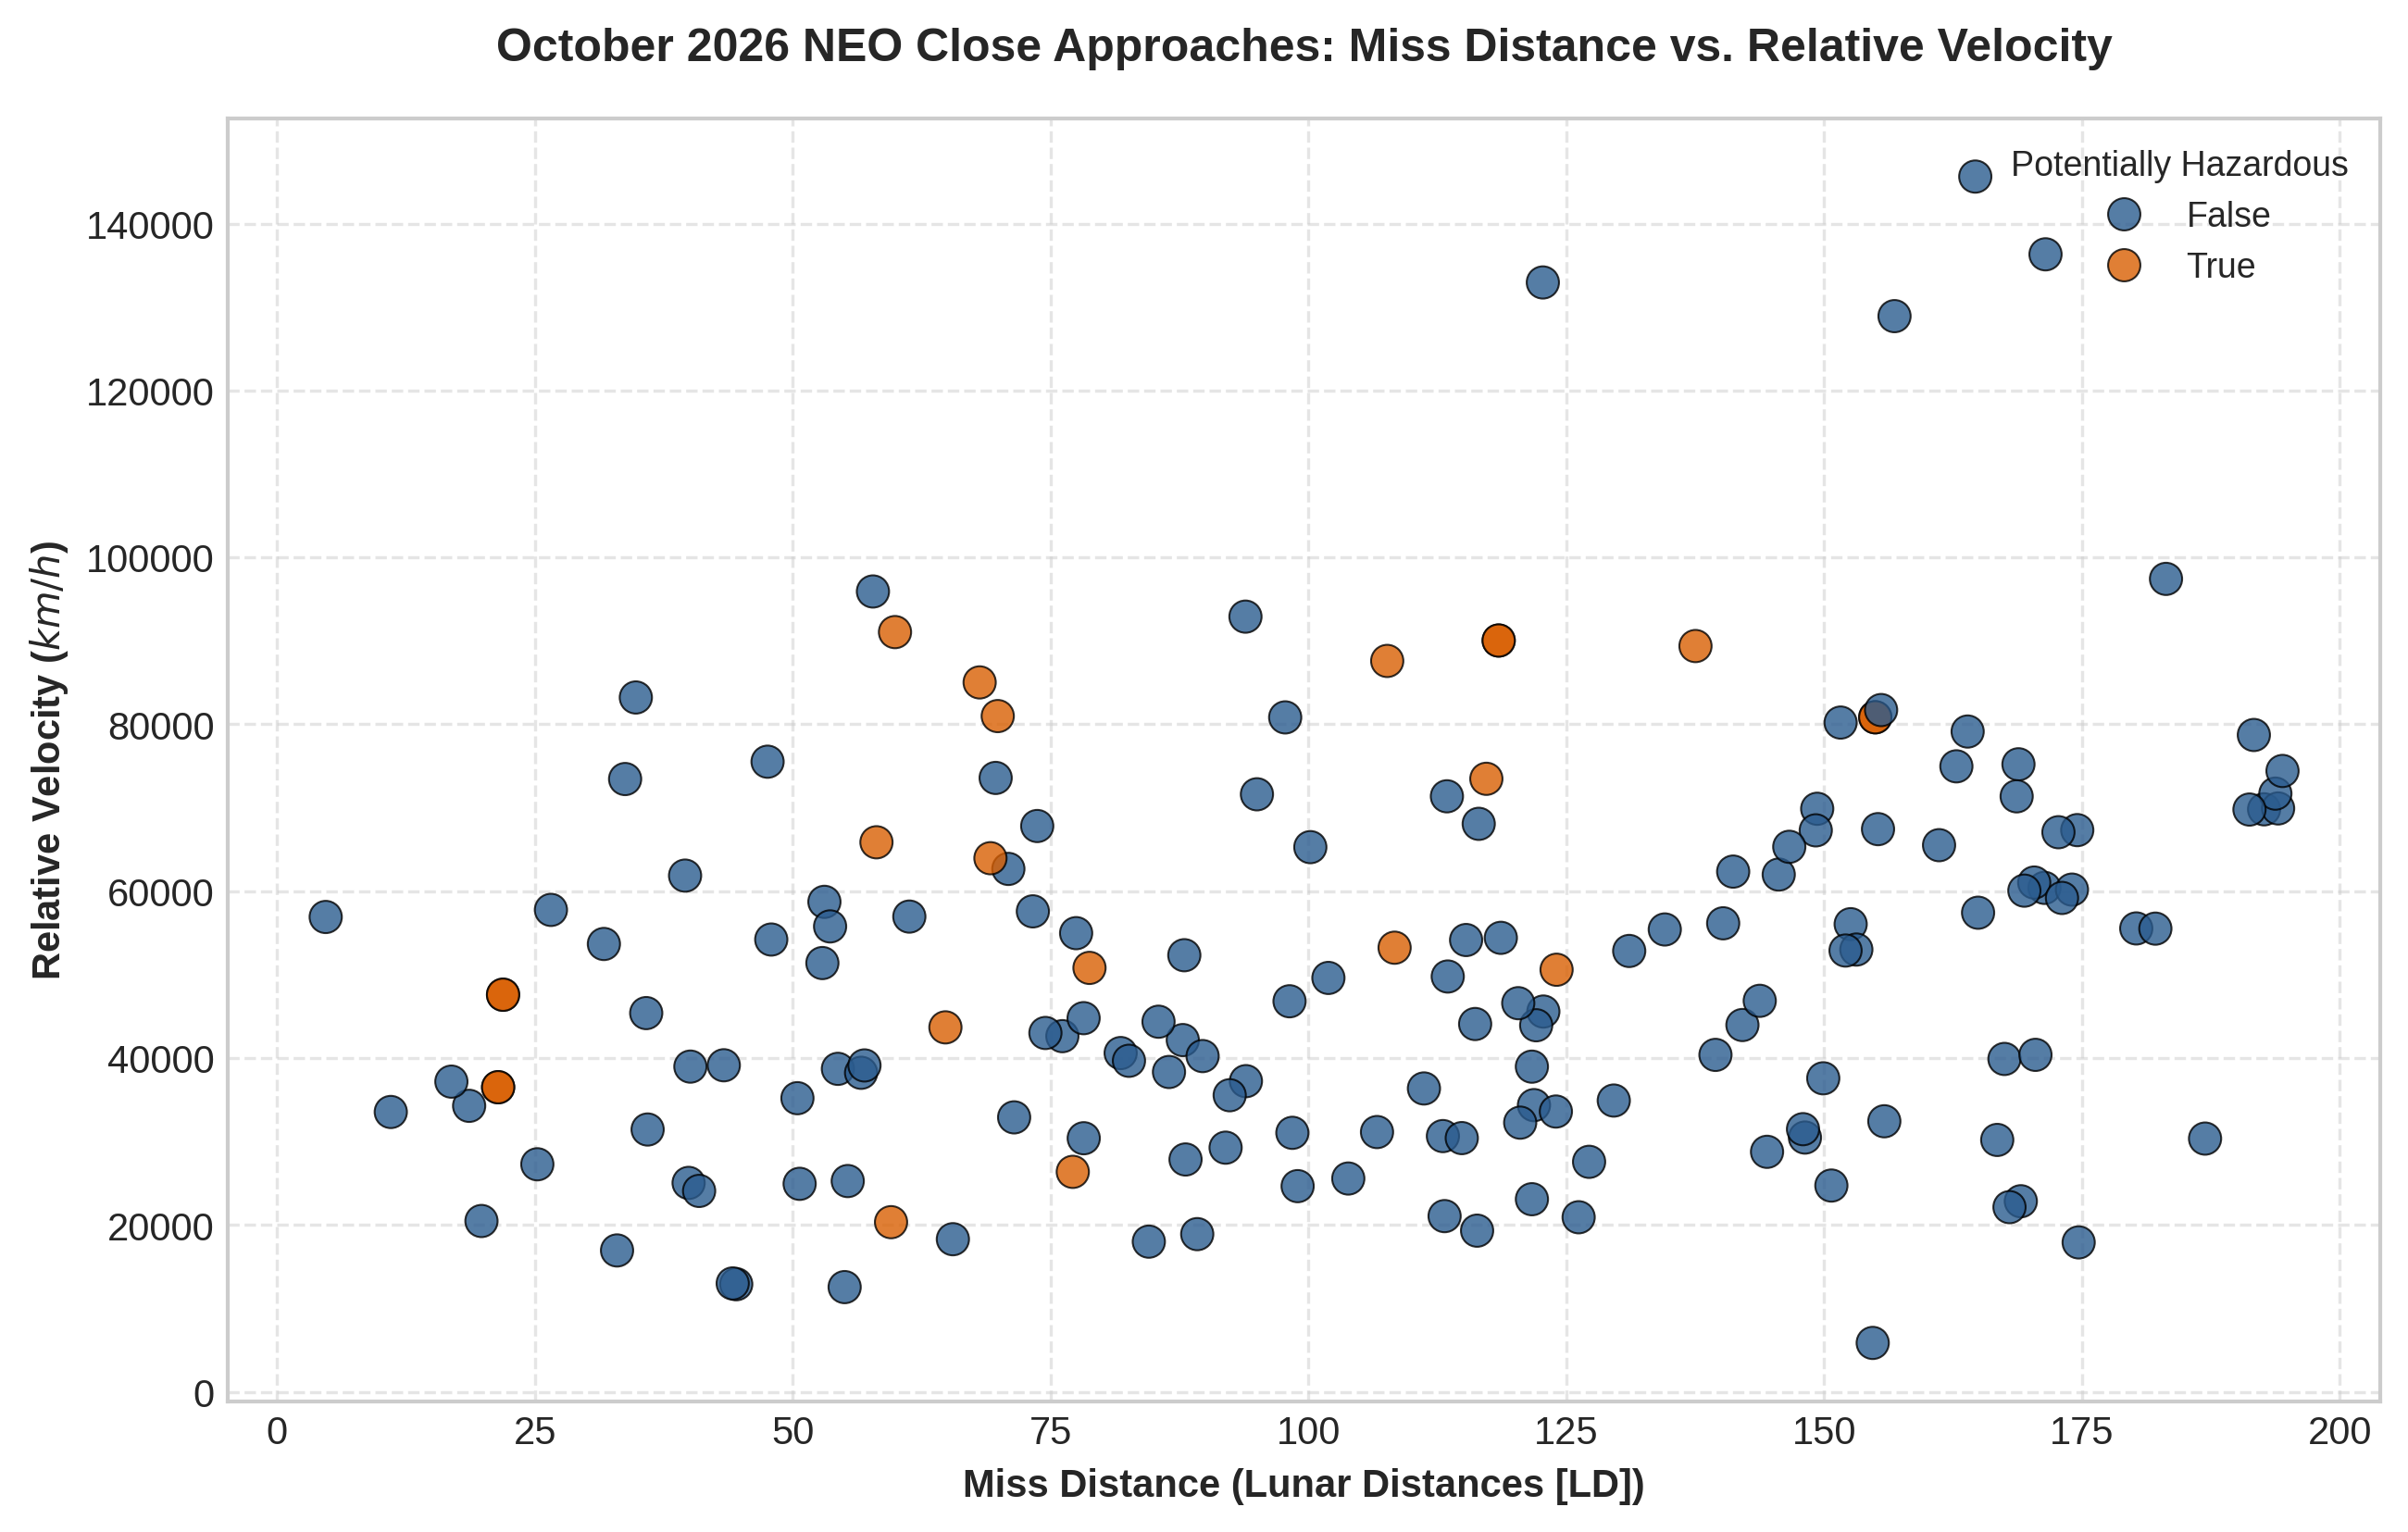

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set scientific plotting style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig, ax = plt.subplots(figsize=(10, 6), dpi=300)

# Define color palette for hazard classification
palette = {False: '#2b5c8f', True: '#d95f02'}

# Scatter plot: Miss Distance (Lunar Distances) vs Relative Velocity (km/h)
sns.scatterplot(
    data=df_neo,
    x='Miss Distance (Lunar Distances)',
    y='Velocity (km/h)',
    hue='Potentially Hazardous',
    palette=palette,
    alpha=0.8,
    s=70,
    edgecolor='k',
    linewidth=0.5,
    ax=ax
)

# Formatting and labeling for publication standards
ax.set_title('October 2026 NEO Close Approaches: Miss Distance vs. Relative Velocity', fontsize=12, fontweight='bold', pad=15)
ax.set_xlabel('Miss Distance (Lunar Distances [LD])', fontsize=10, fontweight='bold')
ax.set_ylabel('Relative Velocity ($km/h$)', fontsize=10, fontweight='bold')

# Legend and grid adjustments
plt.legend(title='Potentially Hazardous', title_fontsize='9', fontsize='9', loc='upper right')
ax.grid(True, linestyle='--', alpha=0.5)

# Ensure output directory exists and save high-resolution figure
vis_dir = '/content/drive/MyDrive/Projects/NEO_Project/visualizations'
os.makedirs(vis_dir, exist_ok=True)
output_fig_path = os.path.join(vis_dir, 'October_2026_NEO_Velocity_vs_MissDistance.png')
plt.savefig(output_fig_path, bbox_inches='tight', dpi=300)

print(f"[Visualization Saved]: High-resolution plot exported successfully to:\n{output_fig_path}")
plt.show()

## Phase 4: Statistical Synthesis & Summary Metrics
In this final phase, we compute aggregate telemetry statistics for the October 2026 dataset, summarizing population counts, hazard ratios, and extreme orbital approach metrics.

In [ ]:
# Compute aggregate summary statistics
total_objects = len(df_neo)
pha_count = df_neo['Potentially Hazardous'].sum()
non_pha_count = total_objects - pha_count
pha_percentage = (pha_count / total_objects) * 100

min_miss_ld = df_neo['Miss Distance (Lunar Distances)'].min()
max_velocity = df_neo['Velocity (km/h)'].max()

print("==================================================")
print("     OCTOBER 2026 NEO MONTHLY TELEMETRY SUMMARY     ")
print("==================================================")
print(f"Total Analyzed Objects      : {total_objects}")
print(f"Non-Hazardous Asteroids     : {non_pha_count} ({100 - pha_percentage:.1f}%)")
print(f"Potentially Hazardous (PHAs): {pha_count} ({pha_percentage:.1f}%)")
print(f"Closest Approach Distance   : {min_miss_ld:.2f} Lunar Distances")
print(f"Maximum Relative Velocity   : {max_velocity:,.2f} km/h")
print("==================================================")

     OCTOBER 2026 NEO MONTHLY TELEMETRY SUMMARY     
Total Analyzed Objects      : 169
Non-Hazardous Asteroids     : 147 (87.0%)
Potentially Hazardous (PHAs): 22 (13.0%)
Closest Approach Distance   : 4.72 Lunar Distances
Maximum Relative Velocity   : 145,638.54 km/h


In [ ]:
import shutil
from google.colab import files

# Package your workspace data and plots into a zip
shutil.make_archive('october_neo_files', 'zip', '/content')
files.download('october_neo_files.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>